In [10]:
%load_ext autoreload
%autoreload 2

import warnings

import numpy as np
import pandas as pd
from IPython.display import display

from thesis.analysis.analyse import plot_behaviour_score_distributions, plot_overlaid_runs
from thesis.analysis.forecast import fit_and_forecast
from thesis.analysis.forecast_success_probs import (
    build_asr_probs_from_fit,
    fit_success_probs,
    pinball_score,
    plot_success_prob_forecast_with_residuals,
)
from thesis.analysis.notebook_helpers import (
    CATEGORIES_BY_NUMBER,
    fit_success_prob_and_build_probs,
    fit_success_probs_bayesian_report,
    investigate_non_convergence,
    load_forecast_run,
    print_variance_decomposition,
    summarize_fit_metrics,
)
from thesis.analysis.plot_forecasts import (
    _prettify,
    asr_at_k_forecast_error,
    build_asr_probs,
    compute_asr_at_k,
    compute_asr_at_k_cumulative,
    plot_asr_at_k_fit,
    plot_asr_at_k_fit_all_families,
    plot_asr_compute_heatmap,
    plot_asr_decomposition,
    plot_asr_forecast_assumptions,
    plot_asr_forecast_vs_observed_scatter_grid,
    plot_asr_forecast_vs_true,
    plot_asr_mean_prob_vs_observed,
    plot_behaviours_by_failure_reason,
    plot_cutoff_fits,
    plot_family_comparison_grid,
    plot_fitted_curves,
    plot_overlaid_by_category,
)
from thesis.analysis.sign_flip_test import test_optimization

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", None)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Config & Load Data

In [11]:
ATTACK_NAME = "GCG"
MODEL_RUNS = {
    "Llama 3.1": "gcg_llama_2400",
    "Gemma 3": "gcg_gemma_1200"
}

loaded = {
    name: load_forecast_run(run, categories_by_number=CATEGORIES_BY_NUMBER, list_passed_in_run=[21, 27, 37, 41, 42, 43, 44, 45, 46, 49, 50, 53, 58, 59, 60, 61, 66, 70, 76, 77, 84, 85, 86, 90, 111, 112, 115, 116, 121, 122, 123, 132, 141, 149, 170, 171, 172, 173, 174, 175])
    for name, run in MODEL_RUNS.items()
}


/Users/anna/Documents/Uni/thesis/src/thesis/analysis/notebook_helpers.py:71: RuntimeWarning: Mean of empty slice
  avg_harmfulness = np.nanmean(all_scores, axis=(1, 2))
/Users/anna/Documents/Uni/thesis/src/thesis/analysis/notebook_helpers.py:72: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var_harmfulness = np.nanvar(all_scores, axis=(1, 2))
/Users/anna/Documents/Uni/thesis/src/thesis/analysis/notebook_helpers.py:76: RuntimeWarning: Mean of empty slice
  success_prob = np.nanmean(success, axis=(1, 2))          # (n_behaviors, n_steps)
/Users/anna/Documents/Uni/thesis/src/thesis/analysis/notebook_helpers.py:77: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var_success = np.nanvar(success_prob, axis=(0))
/Users/anna/Documents/Uni/thesis/src/thesis/analysis/notebook_helpers.py:80: RuntimeWarning: All-NaN slice encountered
  any_sample_above = np.nanmax(success, axis=2)   # max over samples (axis=2) -> (problems, runs, steps)
/Users/anna/Documents/Uni/thesis/src/thesis/analy

(40, 14, 32, 2400)
(40, 14, 32, 2400)
(40, 2400)
(40, 4, 128, 1200)
(40, 4, 128, 1200)
(40, 1200)


In [12]:
_FIRST_MODEL = next(iter(MODEL_RUNS))


/Users/anna/Documents/Uni/thesis/src/thesis/analysis/analyse.py:815: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=legend_fontsize, loc=legend_loc)


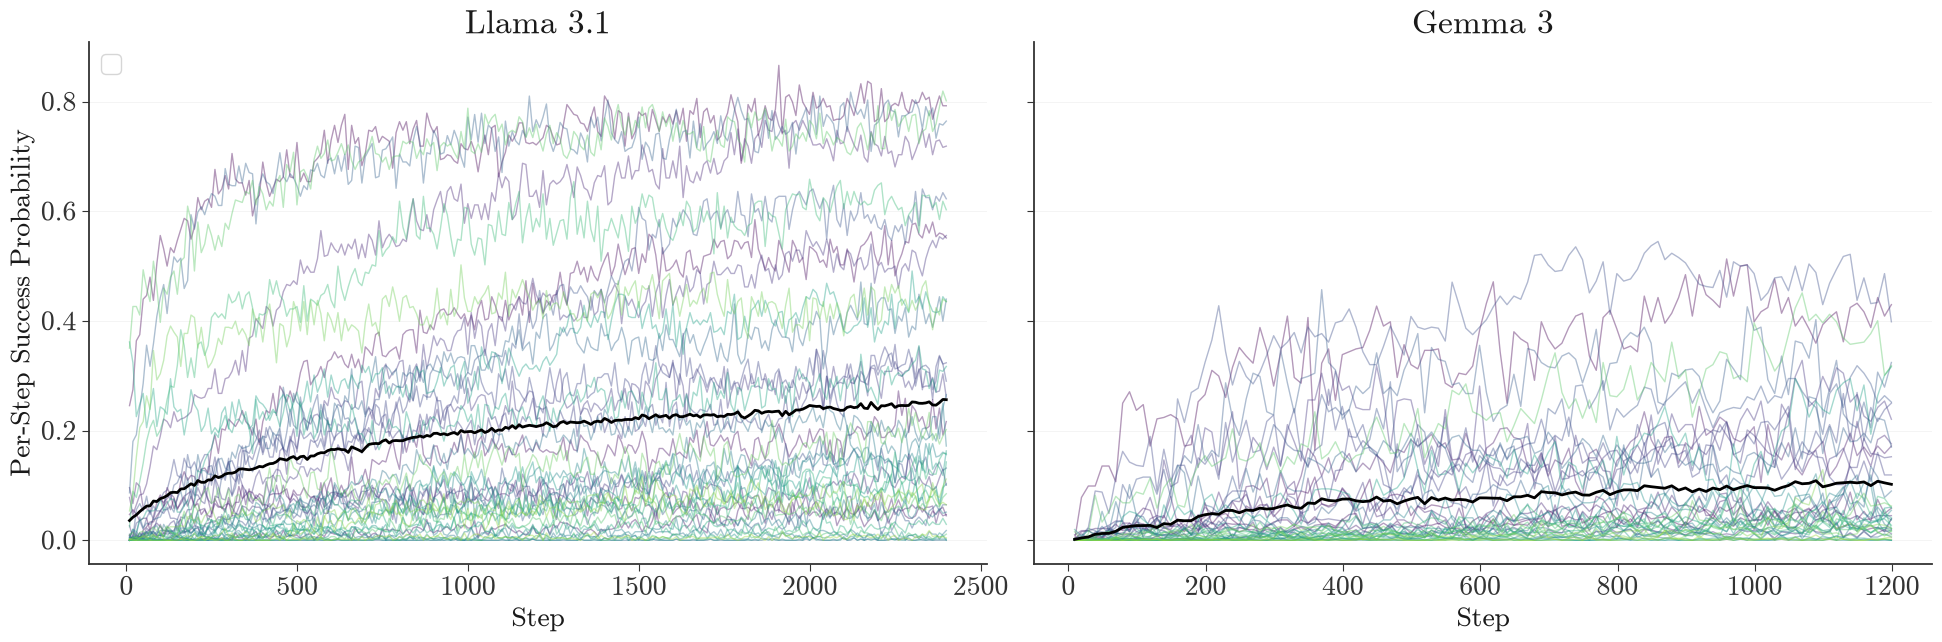

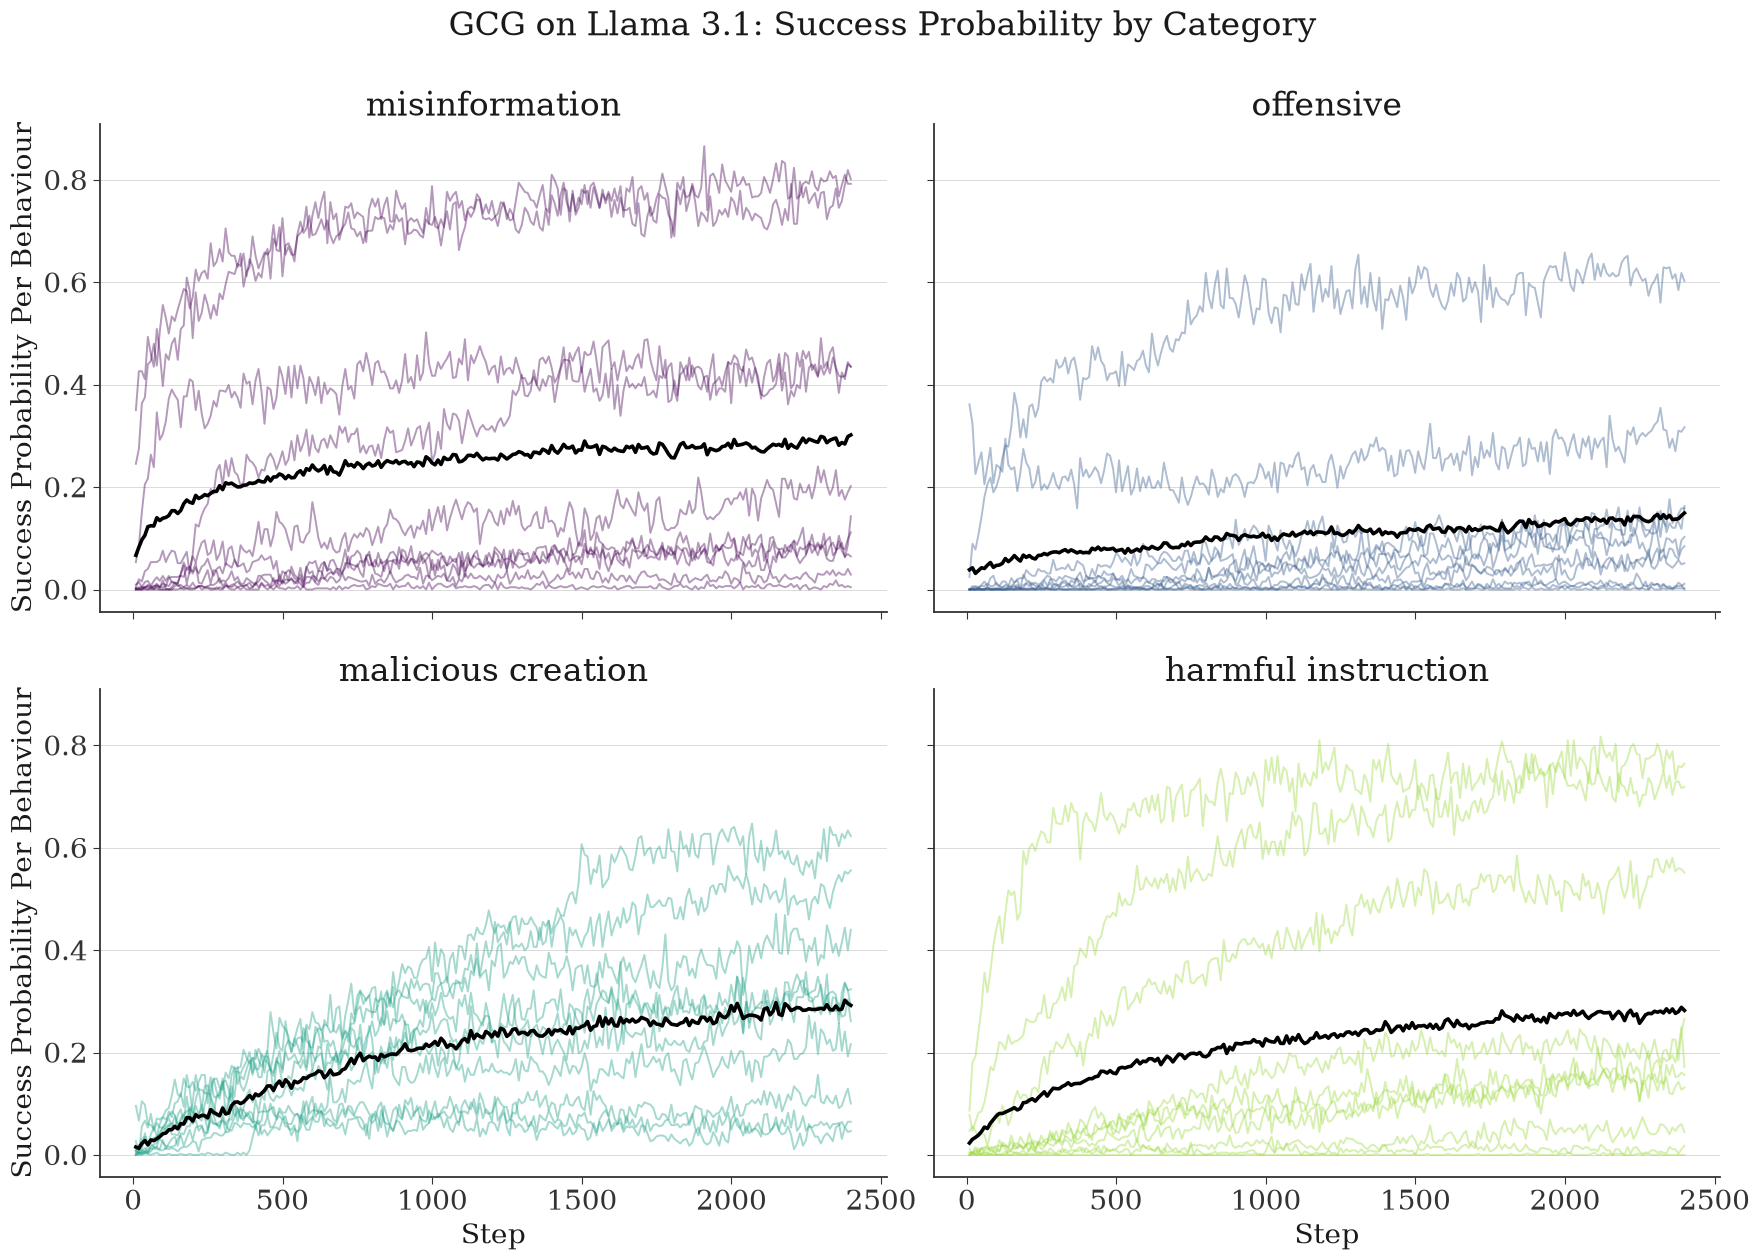

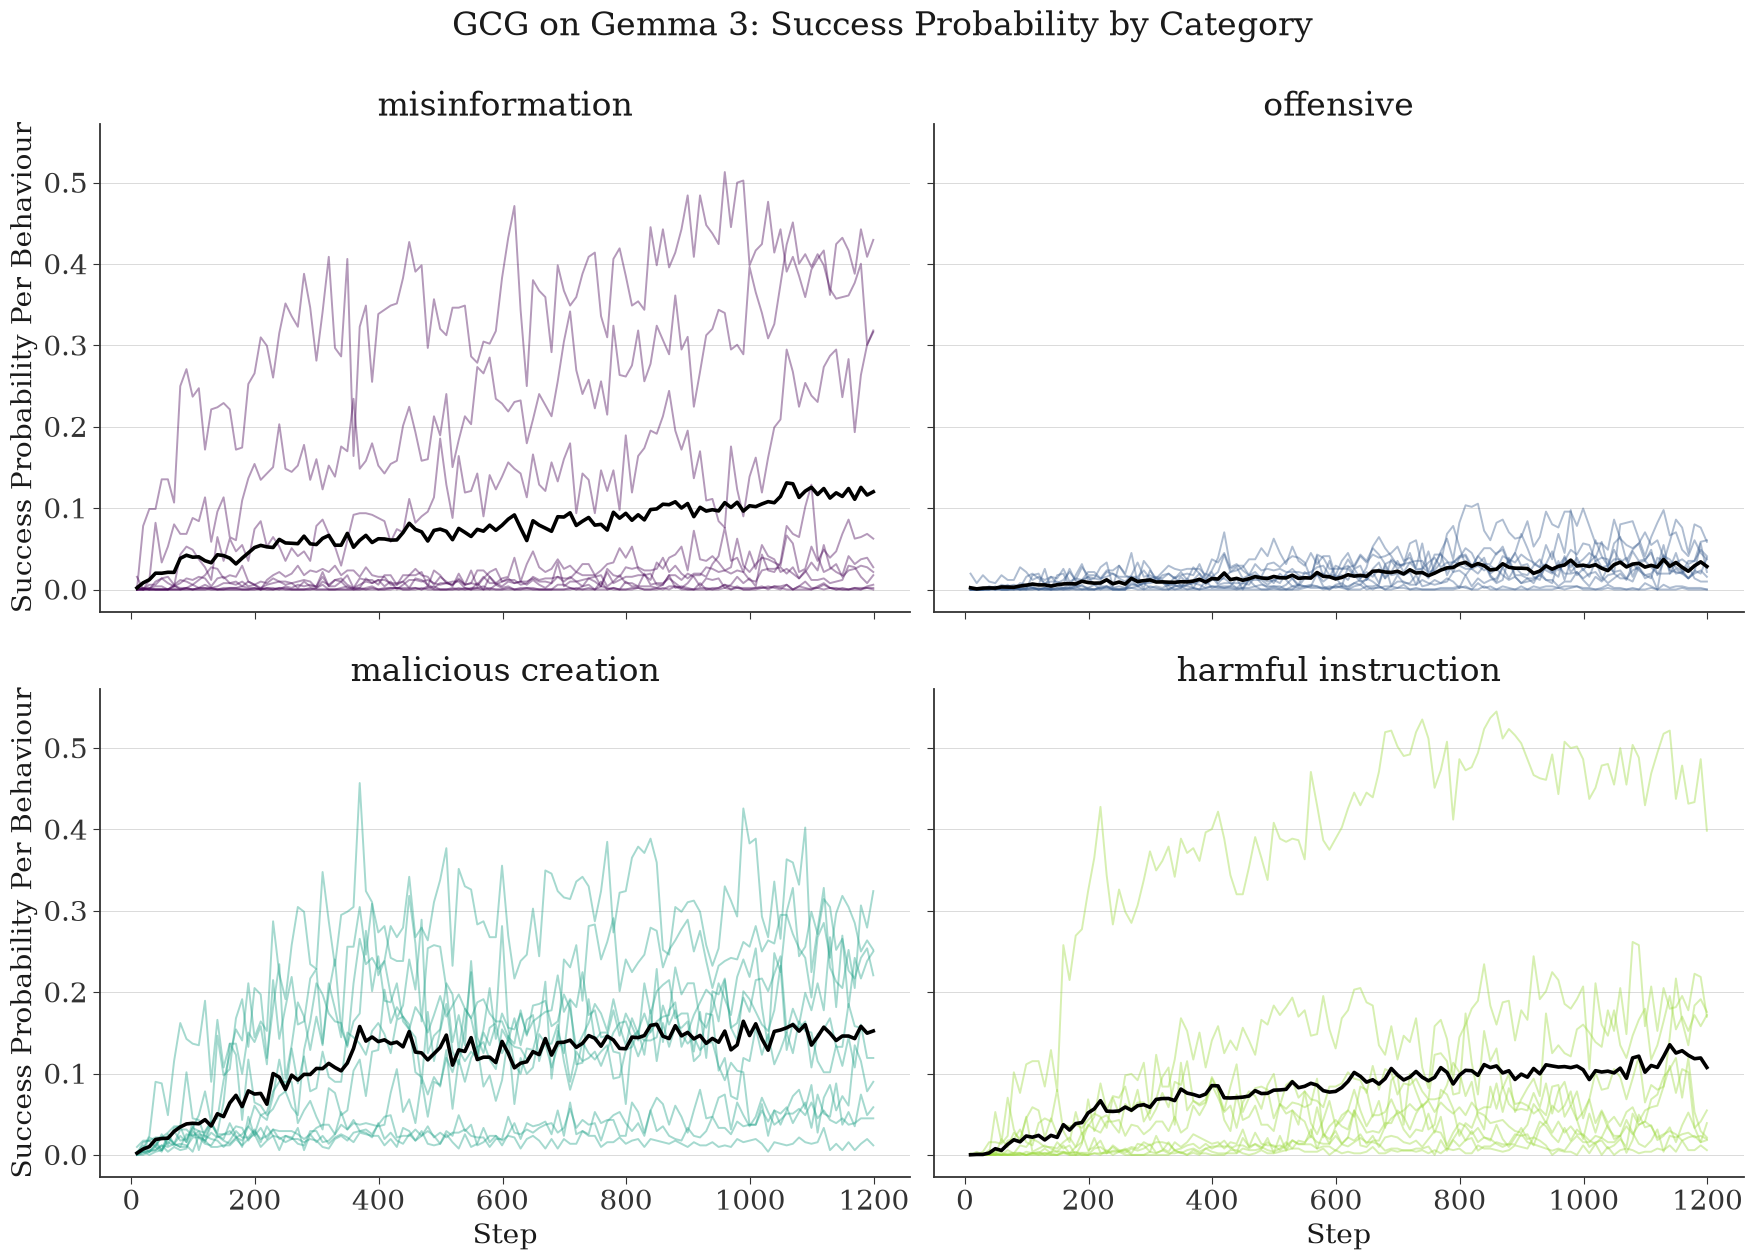

In [13]:
plot_overlaid_runs(
    scores=[loaded[name]["success_prob"] for name in MODEL_RUNS],
    title=list(MODEL_RUNS.keys()),
    y_label="Per-Step Success Probability",
)

for name in MODEL_RUNS:
    display(plot_overlaid_by_category(
        loaded[name]["success_prob"], loaded[name]["categories_to_idx"],
        y_label="Success Probability Per Behaviour",
        title=f"{ATTACK_NAME} on {name}: Success Probability by Category",
    ))


### Fit and forecast ASR Directly

#### ASR@1 / ASR@k Cumulative

In [ ]:
### For Llama
K = 100
CUTOFF = [200, 400, 600, 800, "max"]

pooled_success_llama = success_llama.reshape(success_llama.shape[0], -1, success_llama.shape[-1])
boot1_llama = compute_asr_at_k_cumulative(pooled_success_llama, k=1, n_bootstrap=200, seed=0)
bootk_llama = compute_asr_at_k_cumulative(pooled_success_llama, k=K, n_bootstrap=200, seed=0)

asr1_fit_results_llama = fit_and_forecast(boot1_llama["point"][None, :], cutoffs=CUTOFF, include_aggregate=False)
asrk_fit_results_llama = fit_and_forecast(bootk_llama["point"][None, :], cutoffs=CUTOFF, include_aggregate=False)

asr1_fit_results_llama['row_id'] = 'aggregate'
asrk_fit_results_llama['row_id'] = 'aggregate'

/Users/anna/Documents/Uni/thesis/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Users/anna/Documents/Uni/thesis/src/thesis/analysis/plot_forecasts.py:2430: RuntimeWarning: Mean of empty slice
  "point": np.nanmean(aggregate_draws, axis=0),
/Users/anna/Documents/Uni/thesis/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Users/anna/Documents/Uni/thesis/src/thesis/analysis/plot_forecasts.py:2430: RuntimeWarning: Mean of empty slice
  "point": np.nanmean(aggregate_draws, axis=0),
2026-11-20 14:13:58,246 INFO thesis.analysis.forecast: fit_and_forecast: 1 rows (incl. aggregate=False) x 5 families x 5 cutoffs = 25 fits; 2391/2400 columns observed; n_jobs=-1
2026-11-20 14:14:01,430 INFO thesis.analysis.forecast: fit converged with a soft validation warning: row_id='0' family='stretched_exponential' cutoff=200 

In [ ]:
### For Gemma
K = 100
CUTOFF = [200, 400, 600, 800, "max"]

pooled_success_gemma = success_gemma.reshape(success_gemma.shape[0], -1, success_gemma.shape[-1])
boot1_gemma = compute_asr_at_k_cumulative(pooled_success_gemma, k=1, n_bootstrap=200, seed=0)
bootk_gemma = compute_asr_at_k_cumulative(pooled_success_gemma, k=K, n_bootstrap=200, seed=0)

asr1_fit_results_gemma = fit_and_forecast(boot1_gemma["point"][None, :], cutoffs=CUTOFF, include_aggregate=False)
asrk_fit_results_gemma = fit_and_forecast(bootk_gemma["point"][None, :], cutoffs=CUTOFF, include_aggregate=False)

asr1_fit_results_gemma['row_id'] = 'aggregate'
asrk_fit_results_gemma['row_id'] = 'aggregate'

/Users/anna/Documents/Uni/thesis/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Users/anna/Documents/Uni/thesis/src/thesis/analysis/plot_forecasts.py:2430: RuntimeWarning: Mean of empty slice
  "point": np.nanmean(aggregate_draws, axis=0),
/Users/anna/Documents/Uni/thesis/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Users/anna/Documents/Uni/thesis/src/thesis/analysis/plot_forecasts.py:2430: RuntimeWarning: Mean of empty slice
  "point": np.nanmean(aggregate_draws, axis=0),
2026-11-20 14:14:11,379 INFO thesis.analysis.forecast: fit_and_forecast: 1 rows (incl. aggregate=False) x 5 families x 5 cutoffs = 25 fits; 1191/1200 columns observed; n_jobs=-1
2026-11-20 14:14:11,690 INFO thesis.analysis.forecast: fit converged with a soft validation warning: row_id='0' family='exponential' cutoff=800 warning=ne

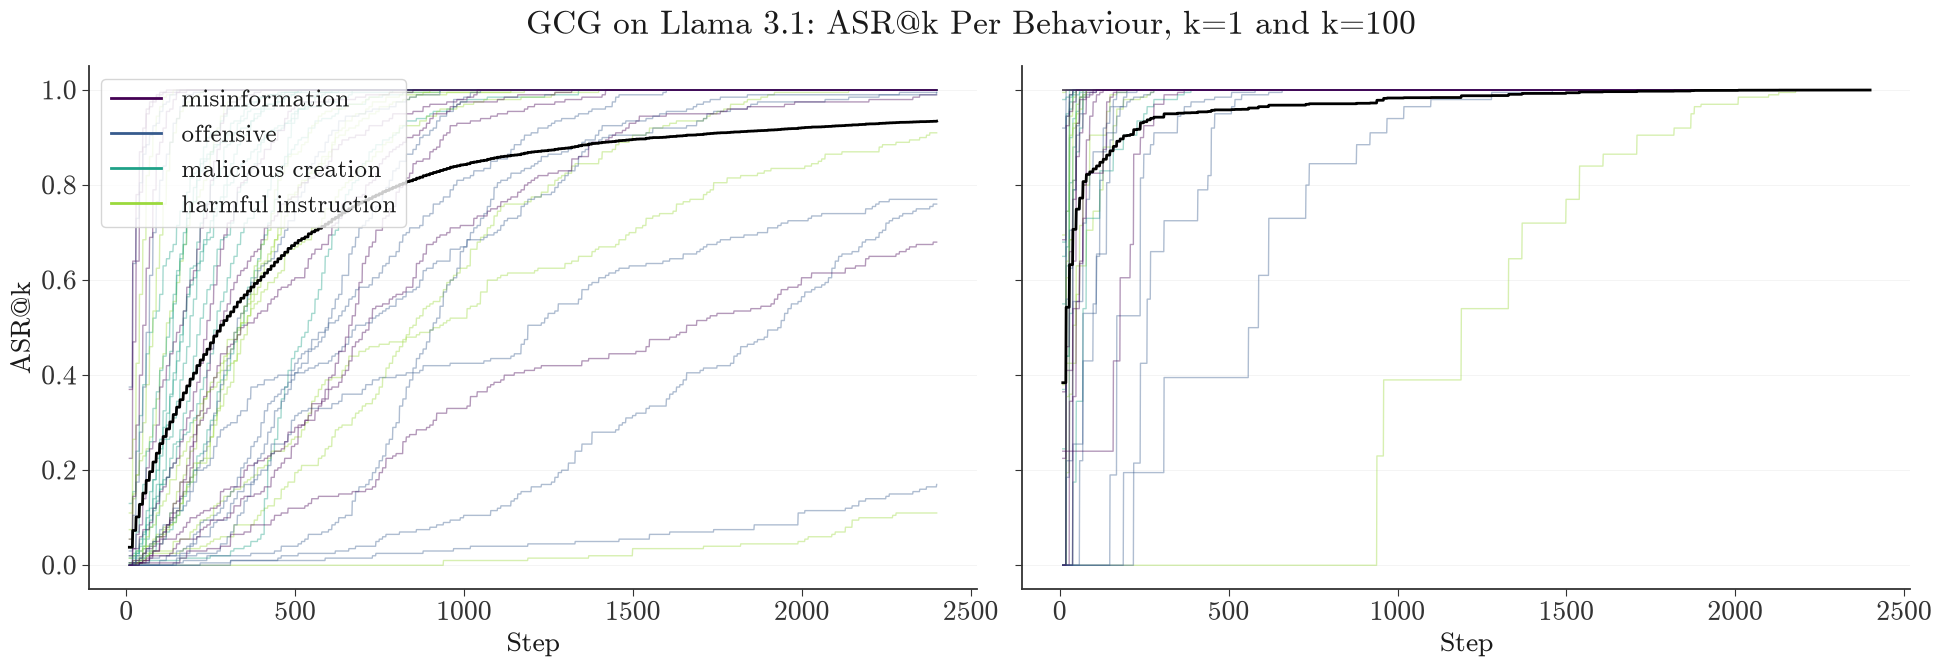

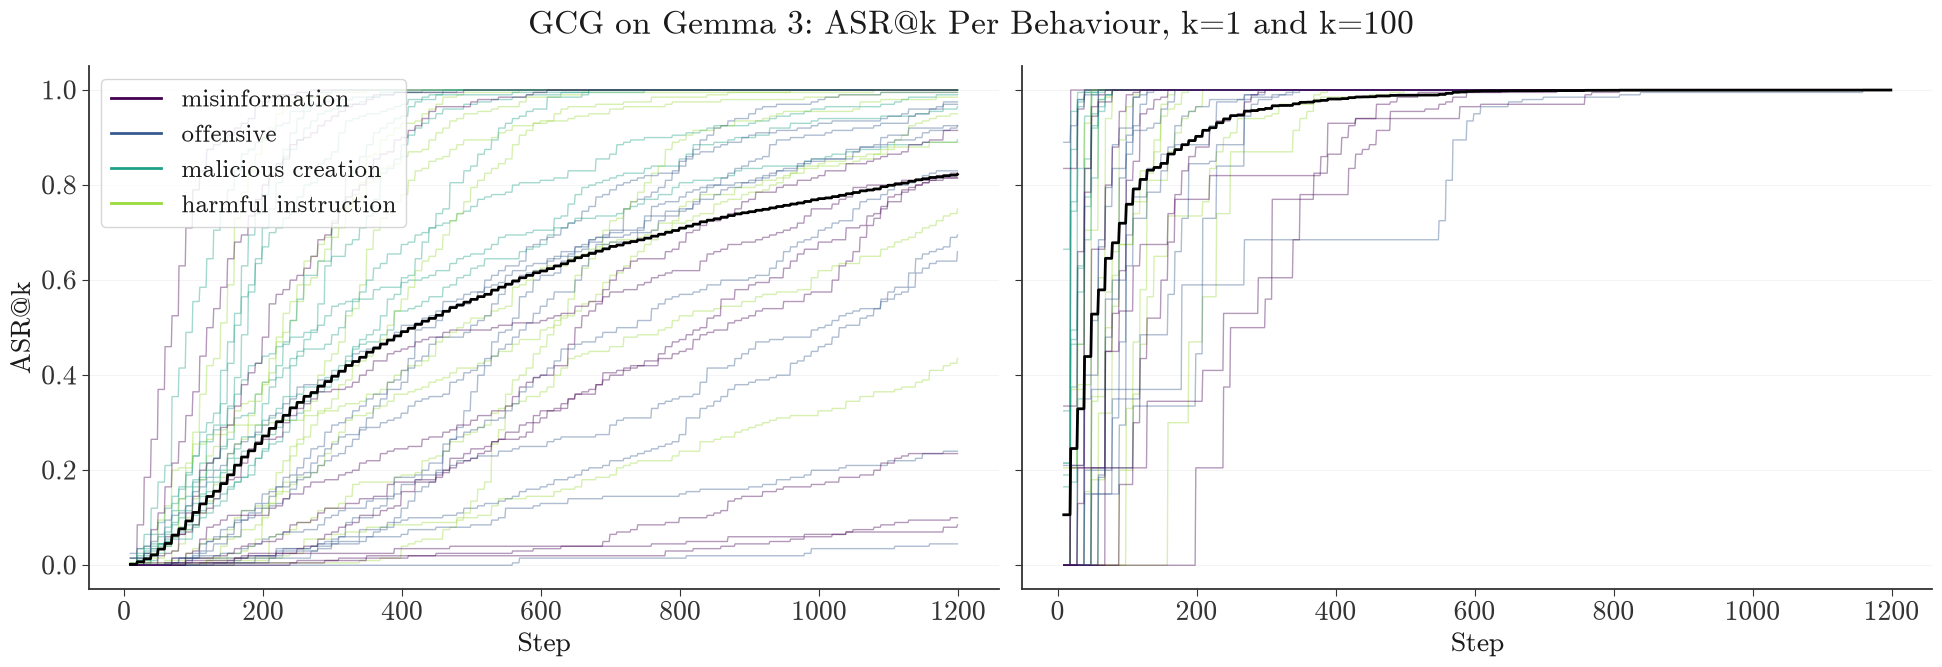

In [8]:
plot_overlaid_runs(
    scores=[boot1_llama["per_behaviour"], bootk_llama["per_behaviour"]],
    y_label="ASR@k",
    title="GCG on Llama 3.1: ASR@k Per Behaviour, k=1 and k=100",
    categories=categories_to_idx,
)


plot_overlaid_runs(
    scores=[boot1_gemma["per_behaviour"], bootk_gemma["per_behaviour"]],
    y_label="ASR@k",
    title="GCG on Gemma 3: ASR@k Per Behaviour, k=1 and k=100",
    categories=categories_to_idx,
)

In [ ]:
plot_family_comparison_grid([[asr1_fit_results_llama, asr1_fit_results_gemma], [asrk_fit_results_llama, asrk_fit_results_gemma]], show_ylabel=False, metric="holdout_endpoint_error", max_metric="in_sample_rmse", highlight_best=True, model_names=["Llama 3.1", "Gemma 3"])

(<Figure size 4400x2520 with 4 Axes>,
 array([[<Axes: title={'left': 'Llama 3.1'}>,
         <Axes: title={'left': 'Gemma 3'}>],
        [<Axes: xlabel='cutoff'>, <Axes: xlabel='cutoff'>]], dtype=object))

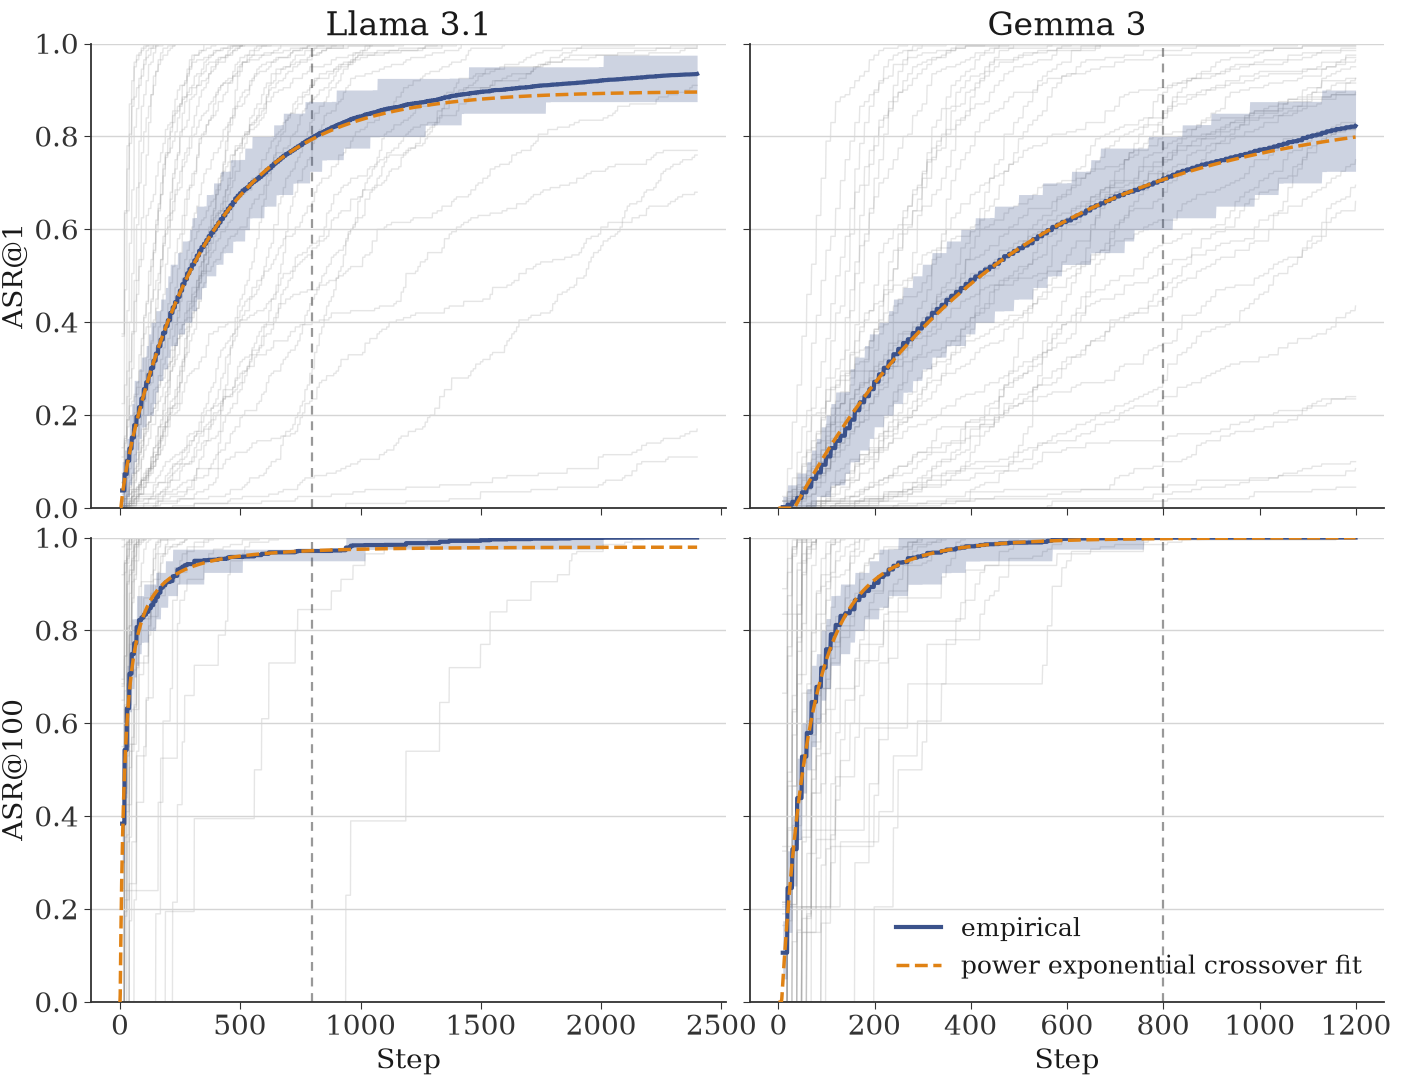

In [ ]:
family1 = "power_exponential_crossover"
familyk = "power_exponential_crossover"

display(plot_asr_at_k_fit(
    [("Llama 3.1", asr1_fit_results_llama, boot1_llama, asrk_fit_results_llama, bootk_llama),
    ("Gemma 3", asr1_fit_results_gemma, boot1_gemma, asrk_fit_results_gemma, bootk_gemma)],
    family1=family1, familyk=familyk, cutoff=800, k=K, 
    # title=f"GCG: Predicted ASR@1 / ASR@{K}"
))


In [ ]:
print(f"GCG Llama: k=1 and k={K}")
display(summarize_fit_metrics(asr1_fit_results_llama, by_behaviour=False, metrics={"holdout_endpoint_error"}, sort_by="holdout_endpoint_error", families={"power_exponential_crossover"}))
display(summarize_fit_metrics(asrk_fit_results_llama, by_behaviour=False, metrics={"holdout_endpoint_error"}, sort_by="holdout_endpoint_error", families={"power_exponential_crossover"}))
print(f"GCG Gemma: k=1 and k={K}")
# display(summarize_fit_metrics(asr1_fit_results_gemma, by_behaviour=False, metrics={"holdout_endpoint_error"}, sort_by="holdout_endpoint_error", families={"power_exponential_crossover"}))
# display(summarize_fit_metrics(asrk_fit_results_gemma, by_behaviour=False, metrics={"holdout_endpoint_error"}, sort_by="holdout_endpoint_error", families={"power_exponential_crossover"}))

GCG Llama: k=1 and k=100


,,in_sample_rmse,holdout_endpoint_error
cutoff,family,,
200,power_exponential_crossover,0.006115,0.054833
400,power_exponential_crossover,0.005149,0.000512
600,power_exponential_crossover,0.004516,0.046692
800,power_exponential_crossover,0.004043,0.038664
max,power_exponential_crossover,0.003206,NaN


,,in_sample_rmse,holdout_endpoint_error
cutoff,family,,
200,power_exponential_crossover,0.017986,0.083329
400,power_exponential_crossover,0.014348,0.001784
600,power_exponential_crossover,0.011905,0.018606
800,power_exponential_crossover,0.010303,0.020764
max,power_exponential_crossover,0.007057,NaN


GCG Gemma: k=1 and k=100


In [ ]:
pec = asr1_fit_results_llama[(asr1_fit_results_llama.family == "power_exponential_crossover") & asr1_fit_results_llama.converged]
pls = asr1_fit_results_llama[(asr1_fit_results_llama.family == "power_law_saturating") & asr1_fit_results_llama.converged]

merged = pec.merge(pls, on="cutoff", suffixes=("_pec", "_pls"))
merged["pi_vs_a"] = merged.params_pec.apply(lambda p: p["a"]) - merged.params_pls.apply(lambda p: p["a"])

# direct curve-shape comparison, not just the asymptote parameter
merged["max_curve_diff"] = merged.apply(
    lambda r: np.nanmax(np.abs(r.predicted_curve_pec - r.predicted_curve_pls)), axis=1
)
print(merged[["cutoff", "pi_vs_a", "max_curve_diff"]])

print("\n")

pls = asr1_fit_results_llama[(asr1_fit_results_llama.family == "power_law_saturating") & asr1_fit_results_llama.converged]
pec = asr1_fit_results_llama[(asr1_fit_results_llama.family == "power_exponential_crossover") & asr1_fit_results_llama.converged]

pls["a_fit"] = pls.params.apply(lambda p: p["a"])
pec["mu_fit"] = pec.params.apply(lambda p: p["mu"])

print(pls[["cutoff", "a_fit"]])
print(pec[["cutoff", "mu_fit"]])

  cutoff       pi_vs_a  max_curve_diff
0    200 -3.702705e-12    1.233312e-01
1    400 -6.211873e-02    3.656669e-02
2    600 -1.109878e-01    1.024555e-01
3    800 -1.026665e-01    6.398946e-02
4    max  7.167773e-09    1.368192e-08


   cutoff     a_fit
10    200  1.000000
11    400  1.000000
12    600  1.000000
13    800  1.000000
14    max  0.948288
   cutoff        mu_fit
20    200  1.731301e-03
21    400  2.309326e-03
22    600  2.635203e-03
23    800  2.550310e-03
24    max  1.385308e-13


In [ ]:
pec = asrk_fit_results_llama[(asrk_fit_results_llama.family == "power_exponential_crossover") & asrk_fit_results_llama.converged]
pls = asrk_fit_results_llama[(asrk_fit_results_llama.family == "power_law_saturating") & asrk_fit_results_llama.converged]

merged = pec.merge(pls, on="cutoff", suffixes=("_pec", "_pls"))
merged["pi_vs_a"] = merged.params_pec.apply(lambda p: p["pi"]) - merged.params_pls.apply(lambda p: p["a"])

# direct curve-shape comparison, not just the asymptote parameter
merged["max_curve_diff"] = merged.apply(
    lambda r: np.nanmax(np.abs(r.predicted_curve_pec - r.predicted_curve_pls)), axis=1
)
print(merged[["cutoff", "pi_vs_a", "max_curve_diff"]])

print("\n")

pls = asrk_fit_results_llama[(asrk_fit_results_llama.family == "power_law_saturating") & asrk_fit_results_llama.converged]
pec = asrk_fit_results_llama[(asrk_fit_results_llama.family == "power_exponential_crossover") & asrk_fit_results_llama.converged]

pls["a_fit"] = pls.params.apply(lambda p: p["a"])
pec["mu_fit"] = pec.params.apply(lambda p: p["mu"])

print(pls[["cutoff", "a_fit"]])
print(pec[["cutoff", "mu_fit"]])

KeyError: 'pi'

In [ ]:
pls = asr1_fit_results_llama[(asr1_fit_results_llama.family == "power_law_saturating") & asr1_fit_results_llama.converged]
pec = asr1_fit_results_llama[(asr1_fit_results_llama.family == "power_exponential_crossover") & asr1_fit_results_llama.converged]

pls["a_fit"] = pls.params.apply(lambda p: p["a"])
pec["mu_fit"] = pec.params.apply(lambda p: p["mu"])

print(pls[["cutoff", "a_fit"]])
print(pec[["cutoff", "mu_fit"]])

   cutoff     a_fit
10    200  1.000000
11    400  1.000000
12    600  1.000000
13    800  1.000000
14    max  0.948436
   cutoff    mu_fit
30    200  0.001386
31    400  0.002119
32    600  0.002573
33    800  0.002487
34    max  0.001359


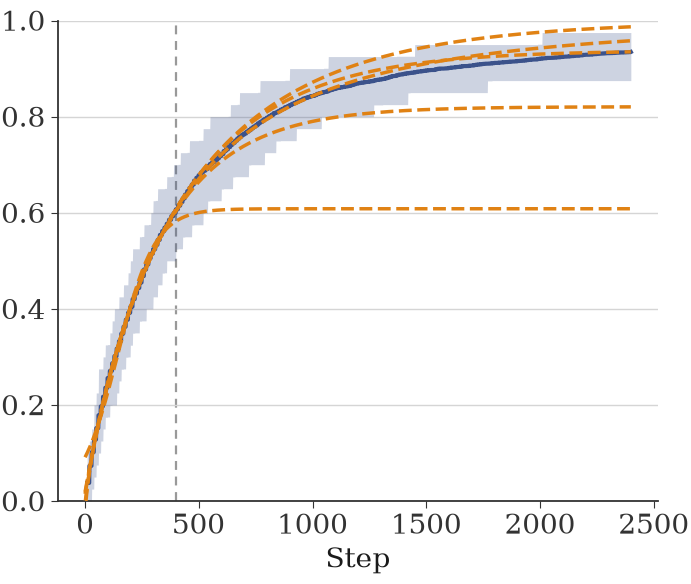

In [ ]:
plot_asr_at_k_fit_all_families("Llama 3.1", asr1_fit_results_llama, boot1_llama, cutoff=400, k=1)

### Fit and forecast Success Probability p(t)

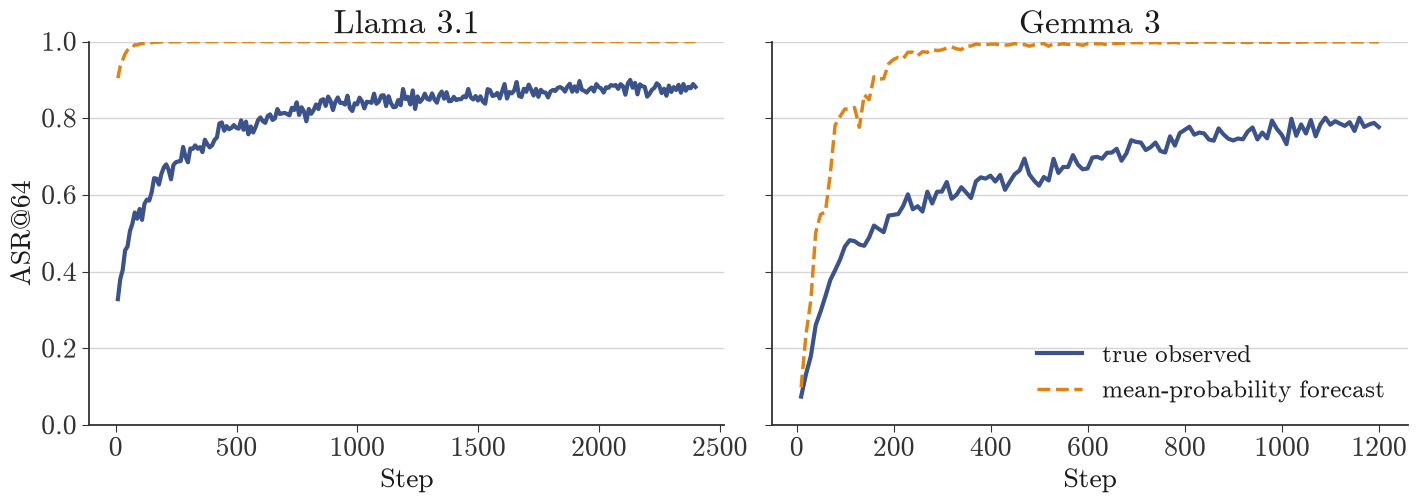

In [14]:
fig, axes = plot_asr_mean_prob_vs_observed(
    [(name, data["success_prob"]) for name, data in loaded.items()], k=64,
)

In [ ]:
# Per-model settings for the success-probability fit/plot cells below. Add a model by adding
# a key here -- everything downstream (fit, convergence check, heatmap, decomposition) loops
# over this dict, so nothing needs to be duplicated per model.
FAMILY = "power_law_saturating"
SUCCESS_PROB_MODELS = {
    name: dict(
        success_prob=data["success_prob"], all_scores=data["all_scores"],
        cutoffs=["max", 400], fit_cutoff_for_probs=400,
        heatmap=dict(cost_ratio=92, mark_cost=None),
        extra_heatmaps=[],
        decomposition=None,
    )
    for name, data in loaded.items()
}


In [16]:
# Fit `FAMILY` to each model's success-probability trajectory across its cutoffs, printing
# convergence + holdout-ASR-error diagnostics (see `fit_success_prob_and_build_probs`), and
# build the forecast-vs-observed table used by the plots below.
success_prob_fit_results = {}
probs_by_model = {}
for name, cfg in SUCCESS_PROB_MODELS.items():
    fit_results, probs = fit_success_prob_and_build_probs(
        name, cfg["success_prob"], cfg["all_scores"], cfg["cutoffs"],
        family=FAMILY, fit_cutoff_for_probs=cfg["fit_cutoff_for_probs"],
    )
    success_prob_fit_results[name] = fit_results
    probs_by_model[name] = probs

2026-11-20 15:30:53,098 INFO thesis.analysis.forecast: fit_and_forecast: 41 rows (incl. aggregate=True) x 1 families x 4 cutoffs = 164 fits; 240/2400 columns observed; n_jobs=-1
2026-11-20 15:30:56,376 WARNING thesis.analysis.forecast: fit failed: row_id='4' family='power_law_saturating' cutoff='max' reason=param_at_bound (n_fit_points=240) -- 100/100 restarts converged numerically but every one was rejected (param_at_boundx100); bound hit by: b@lo=1e-08x63, c@lo=1e-08x46, nu@lo=1e-08x44
2026-11-20 15:31:01,668 INFO thesis.analysis.forecast: fit converged with a soft validation warning: row_id='3' family='power_law_saturating' cutoff=200 warning=negative_at_t0 (n_fit_points=20)
2026-11-20 15:31:04,083 WARNING thesis.analysis.forecast: fit failed: row_id='4' family='power_law_saturating' cutoff=600 reason=param_at_bound (n_fit_points=60) -- 100/100 restarts converged numerically but every one was rejected (param_at_boundx100); bound hit by: c@lo=1e-08x100
2026-11-20 15:31:05,022 WARNING

Llama 3.1:
  power_law_saturating @ cutoff=200: 11/41 did not converge
  power_law_saturating @ cutoff=400: 8/41 did not converge
  power_law_saturating @ cutoff=600: 13/41 did not converge
  power_law_saturating @ cutoff=max: 10/41 did not converge
  cutoff=max, k=1: ASR RMSE (behaviour-averaged) = 0.0207, holdout endpoint error = None
  cutoff=max, k=100: ASR RMSE (behaviour-averaged) = 0.0903, holdout endpoint error = None
  cutoff=200, k=1: ASR RMSE (behaviour-averaged) = 0.0988, holdout endpoint error = 0.14592044328059145
  cutoff=200, k=100: ASR RMSE (behaviour-averaged) = 0.1705, holdout endpoint error = 0.1700417638531262
  cutoff=400, k=1: ASR RMSE (behaviour-averaged) = 0.0683, holdout endpoint error = 0.10074652073159829
  cutoff=400, k=100: ASR RMSE (behaviour-averaged) = 0.1151, holdout endpoint error = 0.09824337348335038
  cutoff=600, k=1: ASR RMSE (behaviour-averaged) = 0.0501, holdout endpoint error = 0.0672586667308052
  cutoff=600, k=100: ASR RMSE (behaviour-average

2026-11-20 15:33:29,972 INFO thesis.analysis.forecast: fit_and_forecast: 41 rows (incl. aggregate=True) x 1 families x 4 cutoffs = 164 fits; 120/1200 columns observed; n_jobs=-1
2026-11-20 15:33:31,686 INFO thesis.analysis.forecast: fit converged with a soft validation warning: row_id='0' family='power_law_saturating' cutoff=400 warning=negative_at_t0 (n_fit_points=40)
2026-11-20 15:33:31,726 INFO thesis.analysis.forecast: fit converged with a soft validation warning: row_id='0' family='power_law_saturating' cutoff='max' warning=negative_at_t0 (n_fit_points=120)
2026-11-20 15:33:37,861 WARNING thesis.analysis.forecast: fit failed: row_id='1' family='power_law_saturating' cutoff=200 reason=param_at_bound (n_fit_points=20) -- 100/100 restarts converged numerically but every one was rejected (param_at_boundx100); bound hit by: c@lo=1e-08x100
2026-11-20 15:33:38,412 INFO thesis.analysis.forecast: fit converged with a soft validation warning: row_id='0' family='power_law_saturating' cutoff=

Gemma 3:
  power_law_saturating @ cutoff=200: 11/41 did not converge
  power_law_saturating @ cutoff=400: 6/41 did not converge
  power_law_saturating @ cutoff=600: 6/41 did not converge
  power_law_saturating @ cutoff=max: 15/41 did not converge
  cutoff=max, k=1: ASR RMSE (behaviour-averaged) = 0.0249, holdout endpoint error = None
  cutoff=max, k=100: ASR RMSE (behaviour-averaged) = 0.1301, holdout endpoint error = None
  cutoff=200, k=1: ASR RMSE (behaviour-averaged) = 0.0606, holdout endpoint error = 0.09791636252385243
  cutoff=200, k=100: ASR RMSE (behaviour-averaged) = 0.1583, holdout endpoint error = 0.14133857026482524
  cutoff=400, k=1: ASR RMSE (behaviour-averaged) = 0.0508, holdout endpoint error = 0.08526149128861109
  cutoff=400, k=100: ASR RMSE (behaviour-averaged) = 0.1459, holdout endpoint error = 0.12137851522994418
  cutoff=600, k=1: ASR RMSE (behaviour-averaged) = 0.0288, holdout endpoint error = 0.039797184127221746
  cutoff=600, k=100: ASR RMSE (behaviour-average

/Users/anna/Documents/Uni/thesis/src/thesis/analysis/plot_forecasts.py:739: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  legend = ax.legend(


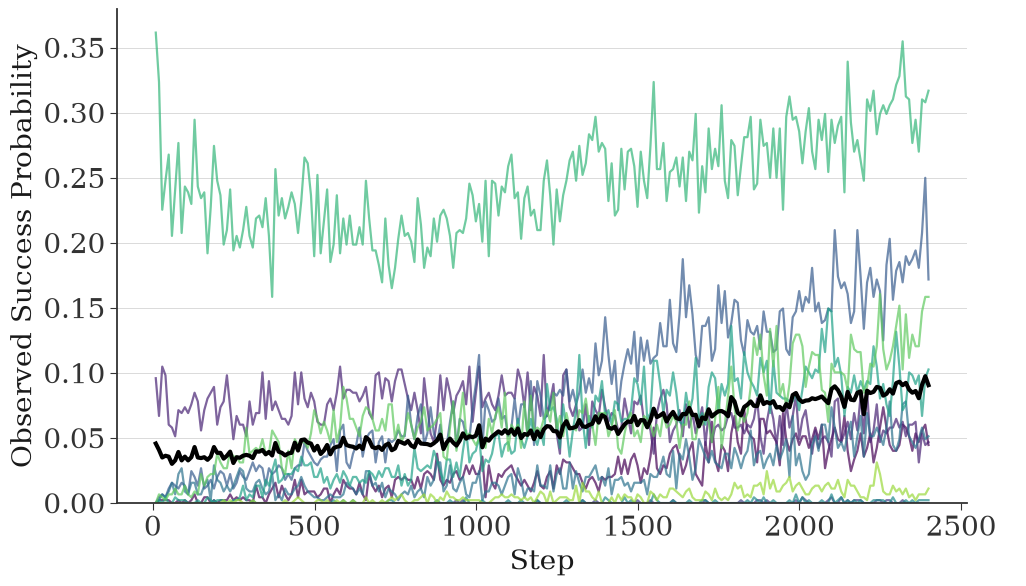

/Users/anna/Documents/Uni/thesis/src/thesis/analysis/plot_forecasts.py:739: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  legend = ax.legend(


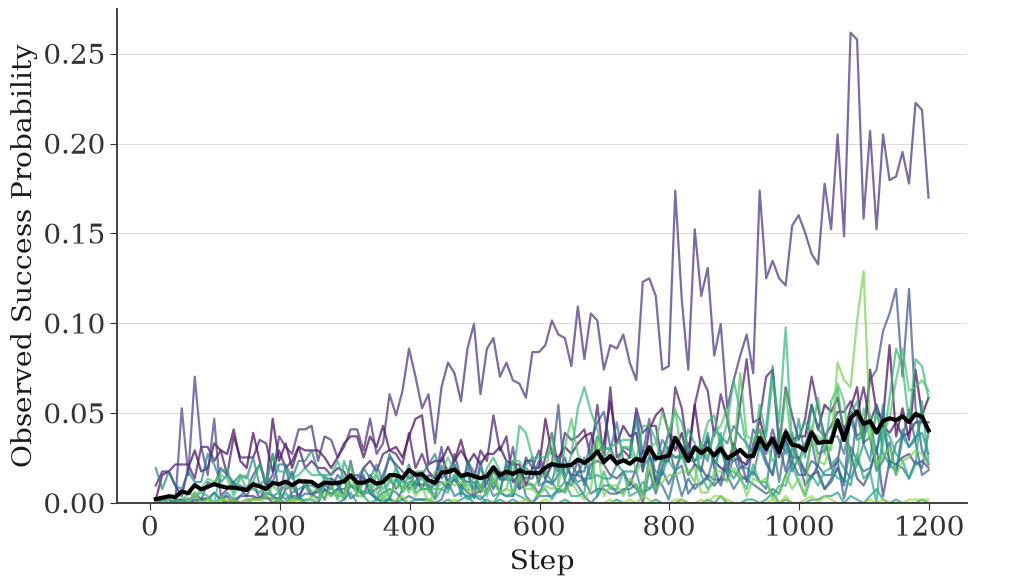

In [22]:
for name, cfg in SUCCESS_PROB_MODELS.items():
    display(plot_behaviours_by_failure_reason(
        success_prob_fit_results[name], cfg["success_prob"],
        family=FAMILY, cutoff="max", failure_reason="param_at_bound",
        y_label="Observed Success Probability",
    ))


In [ ]:
# Example: dig into why a specific (family, failure_reason) combination failed to converge --
# pick the model/reason the convergence printout above actually flagged.
investigate_non_convergence(success_prob_fit_results[_FIRST_MODEL], SUCCESS_PROB_MODELS[_FIRST_MODEL]["success_prob"], "param_at_bound")


row_id
11        3
22        3
24        3
3         3
18        2
25        2
30        2
7         2
13        2
17        2
21        2
19        2
4         2
23        1
28        1
35        1
39        1
6         1
29        1
33        1
38        1
16        1
20        1
27        1
32        1
Name: count, dtype: int64

In [19]:
for name, fit_results in success_prob_fit_results.items():
    print(name)
    display(summarize_fit_metrics(fit_results, metrics=["holdout_rmse"], sort_by="holdout_rmse"))


Llama 3.1


in_sample_rmse           holdout_rmse          
                                      mean    median         mean    median
cutoff family                                                              
200    power_law_saturating       0.012383  0.009883     0.102964  0.075159
400    power_law_saturating       0.014051  0.013379     0.074378  0.043259
600    power_law_saturating       0.017634  0.018516     0.056685  0.047542
max    power_law_saturating       0.020843  0.021996          NaN       NaN

Gemma 3


in_sample_rmse           holdout_rmse          
                                      mean    median         mean    median
cutoff family                                                              
200    power_law_saturating       0.011931  0.005655     0.066005  0.023000
400    power_law_saturating       0.014783  0.007183     0.060861  0.029146
600    power_law_saturating       0.017378  0.008874     0.035898  0.028857
max    power_law_saturating       0.025015  0.026452          NaN       NaN

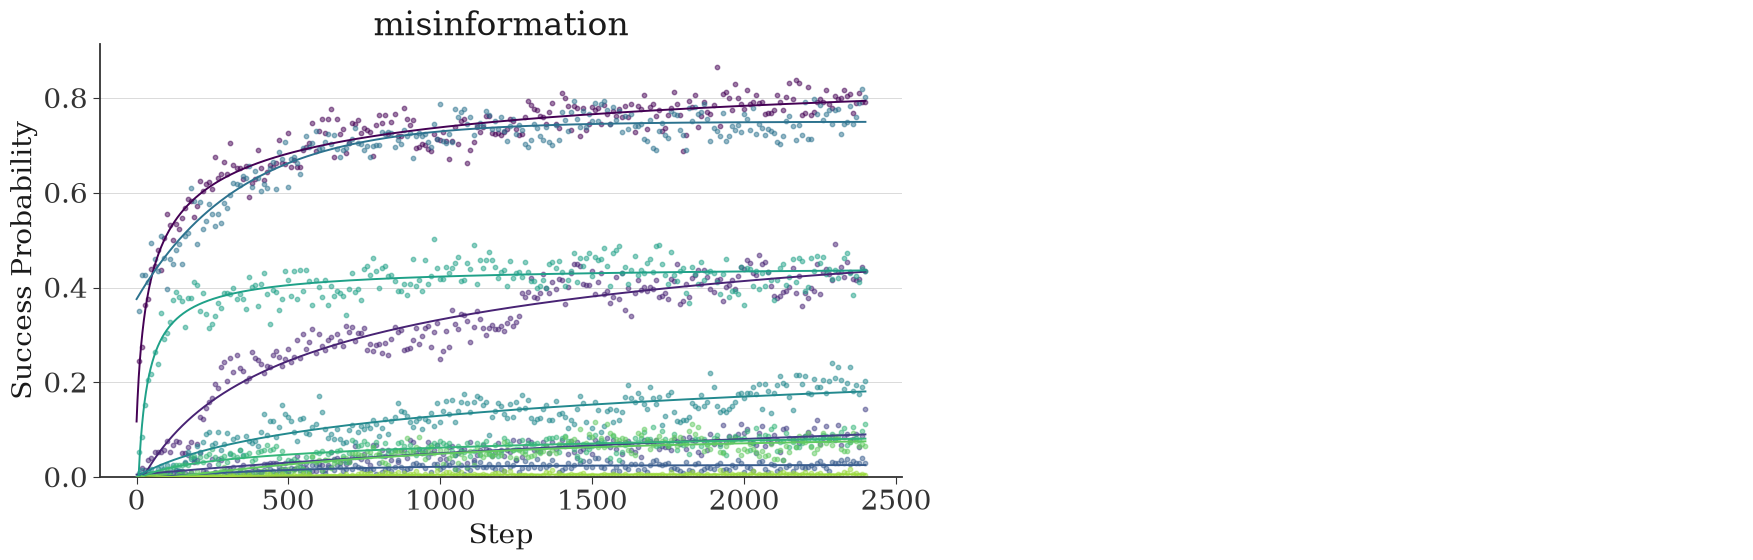

In [20]:
display(plot_fitted_curves(
    success_prob_fit_results[_FIRST_MODEL], SUCCESS_PROB_MODELS[_FIRST_MODEL]["success_prob"],
    family=FAMILY, categories={"misinformation": loaded[_FIRST_MODEL]["categories_to_idx"]["misinformation"]},
    cutoff="max", y_label="Success Probability",
))

,row_id,step,p_forecast,p_true,n_pool,n_succ
0,0,0,0.166536,NaN,NaN,NaN
1,0,1,0.175801,NaN,NaN,NaN
2,0,2,0.184740,NaN,NaN,NaN
3,0,3,0.193373,NaN,NaN,NaN
4,0,4,0.201715,NaN,NaN,NaN
5,0,5,0.209781,NaN,NaN,NaN
6,0,6,0.217586,NaN,NaN,NaN
7,0,7,0.225142,NaN,NaN,NaN
8,0,8,0.232463,NaN,NaN,NaN
9,0,9,0.239558,0.245536,448.0,110.0


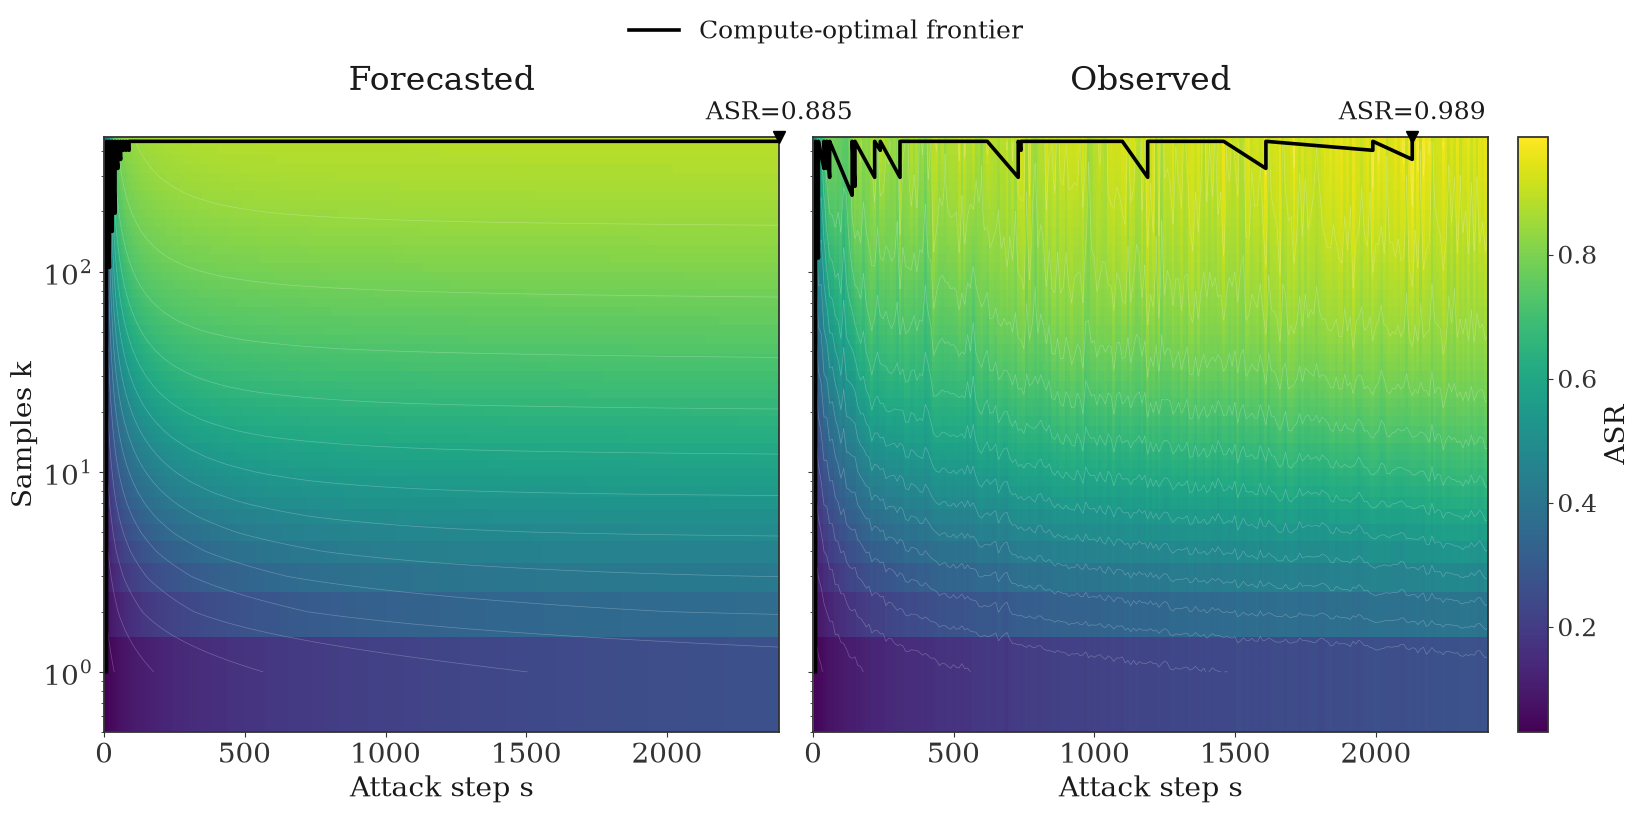

,row_id,step,p_forecast,p_true,n_pool,n_succ
0,0,0,0.000000,NaN,NaN,NaN
1,0,1,0.000000,NaN,NaN,NaN
2,0,2,0.000000,NaN,NaN,NaN
3,0,3,0.000000,NaN,NaN,NaN
4,0,4,0.000000,NaN,NaN,NaN
5,0,5,0.000000,NaN,NaN,NaN
6,0,6,0.000000,NaN,NaN,NaN
7,0,7,0.002414,NaN,NaN,NaN
8,0,8,0.007754,NaN,NaN,NaN
9,0,9,0.012906,0.0,384.0,0.0


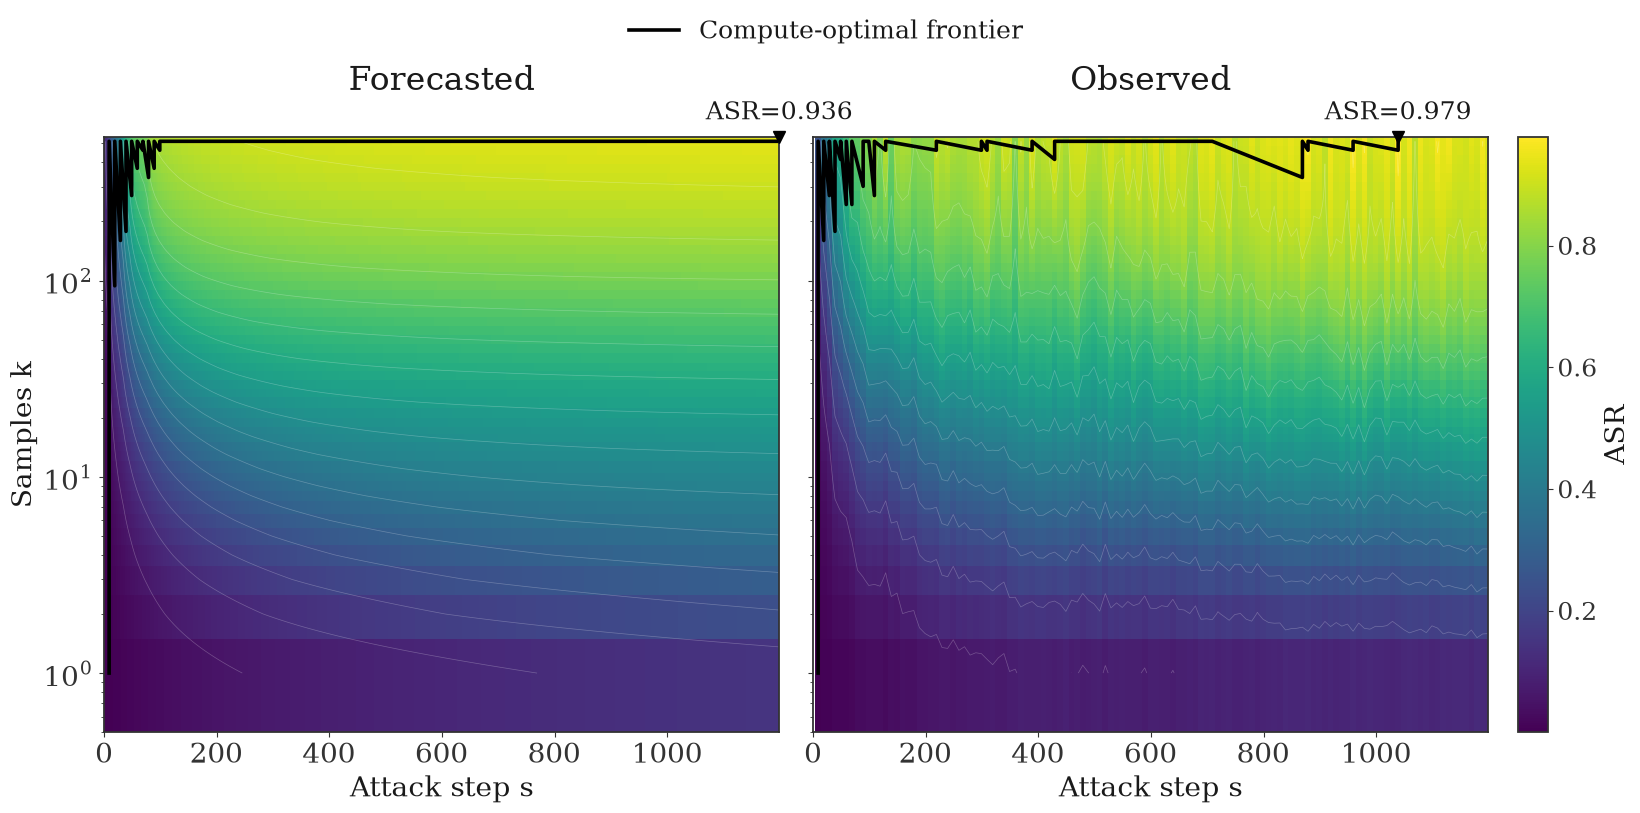

In [21]:
for name, cfg in SUCCESS_PROB_MODELS.items():
    probs = probs_by_model[name]
    display(probs.head(10))

    fig, _ = plot_asr_compute_heatmap(
        probs, s_max=None, match_forecast_steps_to_observed=True, observed_hypergeometric=False,
        **cfg["heatmap"],
    )
    display(fig)
    for extra in cfg.get("extra_heatmaps", []):
        fig, _ = plot_asr_compute_heatmap(
            probs, s_max=None, match_forecast_steps_to_observed=True,
            observed_hypergeometric=False, **extra,
        )
        display(fig)

    if cfg.get("decomposition"):
        fig, _ = plot_asr_decomposition(
            probs, k_max=None, show_mean_probability_curve=False, observed_hypergeometric=False,
            **cfg["decomposition"],
        )
        display(fig)


### Bayesian fits to Success Probs

In [ ]:
# Hierarchical-Bayes counterpart of the fits above (see `fit_success_probs_bayesian_report`).
# `plot_all_cutoffs=False` only plots the first cutoff's heatmap/decomposition (cheaper); set it
# True to see every cutoff, as the original Gemma exploration did.
BAYES_MODELS = {
    "Llama 3.1": dict(
        pooled_success=success_llama.reshape(success_llama.shape[0], -1, success_llama.shape[-1]),
        all_scores=all_scores_llama, step_multiplier=10,
        cutoffs=[200, 400, 600, 800, "max"],
        heatmap=dict(cost_ratio=92, mark_cost=198000),
        decomposition=dict(step=2129, k=448),
        plot_all_cutoffs=False,
    ),
    "Gemma 3": dict(
        pooled_success=success_gemma.reshape(success_gemma.shape[0], -1, success_gemma.shape[-1]),
        all_scores=all_scores_gemma, step_multiplier=10,
        cutoffs=[200, 400, 600, 800, "max"],
        heatmap=dict(cost_ratio=92, mark_cost=8000),
        decomposition=dict(step=69, k=512),
        plot_all_cutoffs=True,
    ),
}

# MCMC per cutoff per model -- the slow part of this notebook. Shrink num_warmup/num_samples
# for a quick smoke test.
bayes_fits = {}
for name, cfg in BAYES_MODELS.items():
    bayes_fits[name] = fit_success_probs_bayesian_report(
        name, cfg["pooled_success"], categories_to_idx, cfg["all_scores"],
        cutoffs=cfg["cutoffs"], step_multiplier=cfg["step_multiplier"],
        num_warmup=2000, num_samples=2000, num_chains=1,
    )


In [ ]:
for name, cfg in BAYES_MODELS.items():
    cutoffs_to_plot = cfg["cutoffs"] if cfg["plot_all_cutoffs"] else cfg["cutoffs"][:1]
    for cutoff in cutoffs_to_plot:
        _, probs_bayes = bayes_fits[name][cutoff]

        fig, _ = plot_asr_compute_heatmap(
            probs_bayes, s_max=None, match_forecast_steps_to_observed=True,
            observed_hypergeometric=False, **cfg["heatmap"],
        )
        display(fig)

        if cfg.get("decomposition"):
            fig, _ = plot_asr_decomposition(
                probs_bayes, k_max=None, show_mean_probability_curve=False,
                observed_hypergeometric=False, **cfg["decomposition"],
            )
            display(fig)


In [ ]:
# Per-run variance analysis, or: why is gemma so much worse?
print_variance_decomposition([
    ("llama", all_scores_llama, bayes_fits["Llama 3.1"]["max"][0]),
    ("gemma", all_scores_gemma, bayes_fits["Gemma 3"]["max"][0]),
])
